# Aggressive vs Safe Action Trajectories (PI-SVGP Model)

Same framework as notebook 03 but using the **PI-SVGP learned dynamics model**
instead of known F1TENTH dynamics.

**Key differences from notebook 03:**
- Dynamics predictions come from a Sparse Variational GP predicting 9 Pacejka tire parameters
- Latent variables inferred from friction via **C_alpha = mu × 100**
- Uses GP **mean** prediction for trajectory rollouts (deterministic per action pair)
- Each action step = 2 substeps of 0.02s (matching the controller)

## C_alpha → Latent Mapping

The model was trained on 3 friction surfaces:

| Task | mu     | C_alpha |
|------|--------|---------|
| 0    | 1.0489 | 104.89  |
| 1    | 0.8642 | 86.42   |
| 2    | 0.4947 | 49.47   |

For arbitrary mu, we compute `C_alpha = mu * 100` and linearly interpolate the latent variables.

## Action Classification

| Category   | Score Range | Description |
|------------|------------|-------------|
| Safe       | < 0.3      | Gentle inputs |
| Moderate   | 0.3 - 0.7  | Normal driving |
| Aggressive | > 0.7      | Pushing towards limits |

In [12]:
import sys, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import yaml
import torch
from PIL import Image
from pathlib import Path

sys.path.insert(0, "..")
from src.track import Track

In [13]:
# ── Vehicle parameters ───────────────────────────────────────────────────
VP = dict(
    mu=1.0489, C_Sf=4.718, C_Sr=5.4562,
    lf=0.15875, lr=0.17145, h=0.074,
    m=3.74, mass=3.74, I=0.04712, Iz=0.04712,
    s_min=-0.4189, s_max=0.4189,
    sv_min=-3.2, sv_max=3.2,
    v_switch=7.319, a_max=9.51,
    v_min=-5.0, v_max=20.0,
    width=0.31, length=0.58,
)
G = 9.81
BASE_DT = 0.02   # PI-SVGP substep
DT = 0.04         # action step = 2 substeps

# ── Load PI-SVGP model ──────────────────────────────────────────────────
# model_path = "../models/pi_svgp_mcts_data/mcts_svgp_best_params.npz"
model_path = "../models/pi_svgp_mcts_fixed/mcts_svgp_fixed.npz"

data = np.load(model_path, allow_pickle=False)

# Kernel hyperparams
theta = torch.tensor(data['model__theta_opt'], dtype=torch.float64)

# Inducing points (augmented: input + latent)
Zx = torch.tensor(data['model__Zx_opt'], dtype=torch.float64)   # (M, 6)
Zh = torch.tensor(data['model__Zh_opt'], dtype=torch.float64)   # (M, 2)
Z_aug = torch.cat([Zx, Zh], dim=1)                              # (M, 8)
M = Z_aug.shape[0]

# Variational parameters
m_opt = torch.tensor(data['model__m_opt'], dtype=torch.float64)            # (M, 9)
m_logstd = torch.tensor(data['model__m_logstd_opt'], dtype=torch.float64)  # (M, 9)
output_bias = torch.tensor(data['model__output_bias_opt'], dtype=torch.float64)  # (9,)

# Task latent means
h_mu_all = data['model__h_mu_opt']  # (3, 2)

# Input scaler
xmean = torch.tensor(data['xscaler__mean'], dtype=torch.float64)
xscale = torch.tensor(data['xscaler__scale'], dtype=torch.float64)

# ── Precompute kernel inverse ────────────────────────────────────────────
def rbf_ard_kernel(X, Z, th):
    ls, sigma = th[:-1], th[-1]
    Xs, Zs = X / ls, Z / ls
    dist = (Xs**2).sum(1, keepdim=True) + (Zs**2).sum(1, keepdim=True).T - 2*Xs@Zs.T
    return (sigma**2) * torch.exp(-0.5 * dist)

K_mm = rbf_ard_kernel(Z_aug, Z_aug, theta) + torch.eye(M, dtype=torch.float64) * 1e-6
K_mm_inv = torch.linalg.inv(K_mm)

# ── C_alpha → latent interpolation ──────────────────────────────────────
c_alpha_anchors = np.array([104.89, 86.42, 49.47])
h_anchors = h_mu_all[:3]
calpha_slopes = np.zeros(h_anchors.shape[1])
calpha_intercepts = np.zeros(h_anchors.shape[1])
for d in range(h_anchors.shape[1]):
    calpha_slopes[d], calpha_intercepts[d] = np.polyfit(c_alpha_anchors, h_anchors[:, d], 1)

def interpolate_hp_mu(c_alpha):
    """Map C_alpha -> latent variables via linear interpolation."""
    return torch.tensor(calpha_slopes * c_alpha + calpha_intercepts, dtype=torch.float64)

print(f"PI-SVGP model loaded: M={M}, Z_aug={Z_aug.shape}")
print(f"C_alpha anchors: {c_alpha_anchors}")
print(f"Latent slopes:     {calpha_slopes}")
print(f"Latent intercepts: {calpha_intercepts}")
# Show latent values for the 3 training tasks
for mu_val, ca in zip([1.0489, 0.8642, 0.4947], c_alpha_anchors):
    hp = interpolate_hp_mu(ca)
    print(f"  mu={mu_val:.4f}  C_alpha={ca:.2f}  -> hp_mu={hp.numpy()}")

PI-SVGP model loaded: M=50, Z_aug=torch.Size([50, 8])
C_alpha anchors: [104.89  86.42  49.47]
Latent slopes:     [ 0.01701038 -0.0027225 ]
Latent intercepts: [-1.44980685 -0.07816852]
  mu=1.0489  C_alpha=104.89  -> hp_mu=[ 0.33441206 -0.36373178]
  mu=0.8642  C_alpha=86.42  -> hp_mu=[ 0.02023031 -0.31344717]
  mu=0.4947  C_alpha=49.47  -> hp_mu=[-0.60830328 -0.21285071]


In [14]:
# ── GP prediction and Pacejka physics (batched) ─────────────────────────
POSITIVE_IDX = [0, 1, 2, 4, 5, 6]  # Bf, Cf, Df, Br, Cr, Dr get softplus


def gp_predict_mean_batch(features_N6, hp_mu):
    """(N,6) -> (N,9) GP posterior mean only (fast, no variance)."""
    feat_norm = (features_N6 - xmean) / xscale
    N = features_N6.shape[0]
    hp_tiled = hp_mu.unsqueeze(0).expand(N, -1)
    X_aug = torch.cat([feat_norm, hp_tiled], dim=1)   # (N, 8)
    K_nm = rbf_ard_kernel(X_aug, Z_aug, theta)        # (N, M)
    al = K_nm @ K_mm_inv                               # (N, M)
    return al @ m_opt + output_bias                    # (N, 9)


def constrain_pacejka(raw):
    """Softplus on Bf,Cf,Df,Br,Cr,Dr. Works on (N,9)."""
    out = raw.clone()
    out[:, POSITIVE_IDX] = torch.nn.functional.softplus(raw[:, POSITIVE_IDX])
    return out


def extract_features_batch(states_N7, actions_N2, dt=BASE_DT):
    """(N,7) states + (N,2) actions -> (N,6) features.
    Features: [VX, VY, YAW_RATE, STEERING_FB, THROTTLE_CMD*dt, STEERING_CMD*dt]"""
    v     = states_N7[:, 3]
    delta = states_N7[:, 2]
    omega = states_N7[:, 5]
    beta  = states_N7[:, 6]
    accel = actions_N2[:, 0]
    sv    = actions_N2[:, 1]
    return torch.stack([
        v * torch.cos(beta),   # VX
        v * torch.sin(beta),   # VY
        omega,                 # YAW_RATE
        delta,                 # STEERING_FB
        accel * dt,            # THROTTLE_CMD * dt
        sv * dt,               # STEERING_CMD * dt
    ], dim=1)


def pacejka_physics_batch(features_N6, params_N9, dt=BASE_DT):
    """(N,6) features, (N,9) constrained params -> (N,3) next [VX,VY,YR]."""
    VX, VY, YR = features_N6[:, 0], features_N6[:, 1], features_N6[:, 2]
    steer = features_N6[:, 3] + features_N6[:, 5]   # delta + sv*dt
    Bf, Cf, Df, Ef   = params_N9[:, 0], params_N9[:, 1], params_N9[:, 2], params_N9[:, 3]
    Br, Cr, Dr, Er, Frx = params_N9[:, 4], params_N9[:, 5], params_N9[:, 6], params_N9[:, 7], params_N9[:, 8]

    alphaf = steer - torch.atan2(VP['lf'] * YR + VY, torch.abs(VX) + 1e-8)
    alphar = torch.atan2(VP['lr'] * YR - VY, torch.abs(VX) + 1e-8)

    Ffy = Df * torch.sin(Cf * torch.atan(Bf * alphaf - Ef * (Bf * alphaf - torch.atan(Bf * alphaf))))
    Fry = Dr * torch.sin(Cr * torch.atan(Br * alphar - Er * (Br * alphar - torch.atan(Br * alphar))))

    dVX = (1 / VP['mass']) * (Frx - Ffy * torch.sin(steer)) + VY * YR
    dVY = (1 / VP['mass']) * (Fry + Ffy * torch.cos(steer)) - VX * YR
    dYR = (1 / VP['Iz']) * (Ffy * VP['lf'] * torch.cos(steer) - Fry * VP['lr'])

    return torch.stack([VX + dVX * dt, VY + dVY * dt, YR + dYR * dt], dim=1)


def kinematic_update_batch(states_N7, body_N3, actions_N2, dt=BASE_DT):
    """(N,7) states, (N,3) body [VX,VY,YR], (N,2) actions -> (N,7) next states."""
    x, y, delta, v, psi = (
        states_N7[:, 0], states_N7[:, 1], states_N7[:, 2],
        states_N7[:, 3], states_N7[:, 4],
    )
    accel = actions_N2[:, 0]
    sv    = actions_N2[:, 1]
    omega_pred = body_N3[:, 2]
    beta_pred  = torch.atan2(body_N3[:, 1], body_N3[:, 0] + 1e-8)
    return torch.stack([
        x + dt * v * torch.cos(beta_pred + psi),
        y + dt * v * torch.sin(beta_pred + psi),
        delta + dt * sv,
        v + dt * accel,
        psi + dt * omega_pred,
        omega_pred,
        beta_pred,
    ], dim=1)


def apply_constraints_batch(states_N7, actions_N2):
    """Apply steering and acceleration constraints (matching simulator)."""
    delta = states_N7[:, 2]
    v     = states_N7[:, 3]
    accel = actions_N2[:, 0].clone()
    sv    = actions_N2[:, 1].clone()

    # Steering constraint
    at_smin = (delta <= VP['s_min']) & (sv <= 0)
    at_smax = (delta >= VP['s_max']) & (sv >= 0)
    sv = torch.where(at_smin | at_smax, torch.zeros_like(sv), sv)
    sv = torch.clamp(sv, VP['sv_min'], VP['sv_max'])

    # Acceleration constraint
    pos_limit = torch.where(
        v > VP['v_switch'],
        VP['a_max'] * VP['v_switch'] / (v + 1e-8),
        torch.full_like(v, VP['a_max']),
    )
    at_vmin = (v <= VP['v_min']) & (accel <= 0)
    at_vmax = (v >= VP['v_max']) & (accel >= 0)
    accel = torch.where(at_vmin | at_vmax, torch.zeros_like(accel), accel)
    accel = torch.maximum(accel, torch.full_like(accel, -VP['a_max']))
    accel = torch.minimum(accel, pos_limit)

    return torch.stack([accel, sv], dim=1)


@torch.no_grad()
def rollout_svgp_batch(state0, actions_N2, hp_mu, horizon=10):
    """
    Roll out N trajectories using PI-SVGP mean prediction.

    state0:     numpy (7,) initial state
    actions_N2: numpy (N, 2) constant (accel, sv) per trajectory
    hp_mu:      torch (2,) latent variables
    horizon:    number of action steps (each = 2 substeps of BASE_DT)

    Returns: numpy (N, horizon+1, 7)
    """
    N = actions_N2.shape[0]
    actions_t = torch.tensor(actions_N2, dtype=torch.float64)
    states = torch.tensor(state0, dtype=torch.float64).unsqueeze(0).expand(N, -1).clone()

    all_states = [states.numpy().copy()]

    for t in range(horizon):
        for _ in range(2):  # 2 substeps of BASE_DT per action step
            c_actions = apply_constraints_batch(states, actions_t)
            features = extract_features_batch(states, c_actions, BASE_DT)
            raw_mean = gp_predict_mean_batch(features, hp_mu)
            constrained = constrain_pacejka(raw_mean)
            body = pacejka_physics_batch(features, constrained, BASE_DT)
            states = kinematic_update_batch(states, body, c_actions, BASE_DT)
        all_states.append(states.numpy().copy())

    return np.stack(all_states, axis=1)  # (N, horizon+1, 7)


# Quick sanity check
test_state = np.array([0.0, 0.0, 0.0, 5.0, 0.0, 0.0, 0.0])
test_actions = np.array([[1.0, 0.0], [-1.0, 0.0], [0.0, 1.0]])
hp_test = interpolate_hp_mu(104.89)
test_traj = rollout_svgp_batch(test_state, test_actions, hp_test, horizon=3)
print(f"Sanity check: input (3, 2) actions -> output {test_traj.shape}")
print(f"Final velocities: {test_traj[:, -1, 3]}")
print("SVGP rollout functions defined.")

Sanity check: input (3, 2) actions -> output (3, 4, 7)
Final velocities: [5.12 4.88 5.  ]
SVGP rollout functions defined.


In [15]:
# ── Aggressiveness classification & random sampling ──────────────────────

def aggressiveness_score(accel, sv):
    """score = sqrt((|accel|/a_max)^2 + (|sv|/sv_max)^2) / sqrt(2) in [0, 1]."""
    a_norm = abs(accel) / VP['a_max']
    s_norm = abs(sv) / VP['sv_max']
    return math.sqrt(a_norm**2 + s_norm**2) / math.sqrt(2)


def classify_action(accel, sv):
    score = aggressiveness_score(accel, sv)
    if score < 0.3:
        return 'safe'
    elif score < 0.7:
        return 'moderate'
    else:
        return 'aggressive'


def sample_actions(n, category, rng=None):
    """Sample n random (accel, sv) pairs within a category.

    Sampling uses polar coordinates in normalized action space:
        a_norm = accel / a_max,  s_norm = sv / sv_max
        score  = r / sqrt(2)

    Returns: (n, 2) array of (accel, sv) pairs
    """
    if rng is None:
        rng = np.random.default_rng()

    score_ranges = {
        'safe':       (0.0, 0.3),
        'moderate':   (0.3, 0.7),
        'aggressive': (0.7, 1.0),
    }
    lo, hi = score_ranges[category]
    r_lo = lo * math.sqrt(2)
    r_hi = hi * math.sqrt(2)

    results = []
    while len(results) < n:
        batch = max(n * 3, 1000)
        angles = rng.uniform(0, 2 * math.pi, batch)
        r = np.sqrt(rng.uniform(r_lo**2, r_hi**2, batch))
        a_norm = r * np.cos(angles)
        s_norm = r * np.sin(angles)
        mask = (np.abs(a_norm) <= 1.0) & (np.abs(s_norm) <= 1.0)
        a_norm, s_norm = a_norm[mask], s_norm[mask]
        for a, s in zip(a_norm, s_norm):
            results.append((a * VP['a_max'], s * VP['sv_max']))
            if len(results) >= n:
                break

    return np.array(results[:n])


# Demo
rng = np.random.default_rng(42)
for cat in ['safe', 'moderate', 'aggressive']:
    samples = sample_actions(5, cat, rng)
    print(f"\n{cat.upper()} (5 samples):")
    for accel, sv in samples:
        score = aggressiveness_score(accel, sv)
        print(f"  accel={accel:>7.2f}  sv={sv:>6.2f}  score={score:.3f}")


SAFE (5 samples):
  accel=   0.15  sv= -0.33  score=0.075
  accel=  -2.53  sv=  0.34  score=0.203
  accel=   0.91  sv= -0.38  score=0.108
  accel=  -0.51  sv= -0.50  score=0.117
  accel=   2.66  sv=  0.60  score=0.239

MODERATE (5 samples):
  accel=   4.81  sv= -2.45  score=0.649
  accel=  -7.27  sv=  0.86  score=0.572
  accel=   5.58  sv= -0.57  score=0.434
  accel=  -4.89  sv= -2.29  score=0.623
  accel=   3.53  sv=  1.06  score=0.352

AGGRESSIVE (5 samples):
  accel=  -9.35  sv= -0.77  score=0.716
  accel=  -8.54  sv= -2.45  score=0.834
  accel=   9.37  sv= -1.49  score=0.771
  accel=  -9.48  sv= -1.38  score=0.768
  accel=  -6.56  sv= -3.12  score=0.844


In [16]:
# ── Load trajectory data ─────────────────────────────────────────────────

CSV_PATH = (
    "../results/mcts_pi_svgp_cs_extract_YasMarina_10/"
    "traj_config_mcts_dpw_pi_svgp_cpp_cs_extract_s42_YasMarina_10_20260219_110439.csv"
)

TRACK_NAME = "YasMarina"
FRICTION_ID = "10489"  # for map/centerline paths


def load_trajectory_df(csv_path):
    df = pd.read_csv(csv_path, comment="#")
    for col in ['pred_vx', 'pred_vy', 'pred_omega']:
        if col in df.columns:
            df = df.drop(col, axis=1)
    for col in ['Aa_action_list', 'Asv_action_list']:
        if col in df.columns:
            df[col] = df[col].apply(
                lambda s: np.array([float(x) for x in str(s).split(';')])
                if pd.notna(s) and str(s).strip() else np.array([])
            )
    return df


df = load_trajectory_df(CSV_PATH)
print(f"Loaded {len(df)} rows from CSV")
print(f"Velocity range: [{df.S_vel.min():.2f}, {df.S_vel.max():.2f}] m/s")
print(f"Steering range: [{df.S_delta.min():.4f}, {df.S_delta.max():.4f}] rad")

Loaded 3048 rows from CSV
Velocity range: [0.00, 8.79] m/s
Steering range: [-0.4100, 0.4662] rad


In [17]:
# ── Load map and track boundaries ────────────────────────────────────────

MAPS_DIR = Path("../maps")


def load_map_and_track(track_name, friction_id, maps_dir=MAPS_DIR):
    map_dir = maps_dir / f"{track_name}_{friction_id}"

    map_img = np.array(
        Image.open(map_dir / f"{track_name}_map.png").transpose(Image.FLIP_TOP_BOTTOM)
    ).astype(np.float64)

    with open(map_dir / f"{track_name}_map.yaml") as f:
        meta = yaml.safe_load(f)
    res = meta["resolution"]
    ox, oy = meta["origin"][0], meta["origin"][1]
    h_px, w_px = map_img.shape[:2]
    extent = [ox, ox + w_px * res, oy, oy + h_px * res]

    centerline_path = str(map_dir / f"{track_name}_centerline.csv")
    track_obj = Track(centerline_path)

    return map_img, extent, track_obj


map_img, extent, track_obj = load_map_and_track(TRACK_NAME, FRICTION_ID)
print(f"Track: {track_obj.n_points} centerline pts, length = {track_obj.total_length:.1f} m")

Track: 1110 centerline pts, length = 398.0 m


In [18]:
# ── Main plotting function ───────────────────────────────────────────────

CATEGORY_COLORS = {
    'aggressive': 'red',
    'moderate':   'orange',
    'safe':       'green',
}


def plot_trajectories_svgp(
    row_idx,
    df,
    track_obj,
    map_img=None,
    extent=None,
    mu=None,
    horizon=10,
    lane_width=1.1,
    zoom_pad=3.0,
    figsize=(14, 10),
    n_aggressive=100,
    n_moderate=100,
    n_safe=100,
    seed=42,
):
    """
    Sample random action pairs per category, roll out using PI-SVGP, and plot.

    Parameters
    ----------
    row_idx : int
        Row in DataFrame for the starting state.
    mu : float or None
        Friction coefficient. C_alpha = mu * 100 is used for latent inference.
        If None, defaults to VP['mu'] = 1.0489.
    horizon : int
        Number of action steps per rollout (each = 2 substeps of 0.02s).
    lane_width : float
        Controller corridor width (meters).
    n_aggressive, n_moderate, n_safe : int
        Number of trajectories to sample per category. Set to 0 to skip.
    seed : int
        RNG seed for reproducibility.
    """
    row = df.iloc[row_idx]
    state0 = np.array([
        row.S_x, row.S_y, row.S_delta, row.S_vel,
        row.S_psi, row.S_omega, row.S_beta,
    ])

    mu_val = mu if mu is not None else VP['mu']
    c_alpha = mu_val * 100.0
    hp_mu = interpolate_hp_mu(c_alpha)

    print(f"Starting state (row {row_idx}):")
    print(f"  x={state0[0]:.4f}  y={state0[1]:.4f}  delta={state0[2]:.4f}")
    print(f"  v={state0[3]:.2f} m/s  psi={state0[4]:.4f}  omega={state0[5]:.4f}  beta={state0[6]:.6f}")
    print(f"  mu={mu_val}  C_alpha={c_alpha:.2f}  hp_mu={hp_mu.numpy()}")
    print(f"  horizon={horizon}  dt={DT}")
    print(f"  Sampling: {n_aggressive} aggressive, {n_moderate} moderate, {n_safe} safe")

    rng = np.random.default_rng(seed)

    # Sample actions per category
    categories = []
    if n_aggressive > 0:
        categories.append(('aggressive', sample_actions(n_aggressive, 'aggressive', rng)))
    if n_moderate > 0:
        categories.append(('moderate', sample_actions(n_moderate, 'moderate', rng)))
    if n_safe > 0:
        categories.append(('safe', sample_actions(n_safe, 'safe', rng)))

    # Roll out all trajectories (batched per category)
    all_trajs = {}
    off_track_counts = {}
    for cat, action_pairs in categories:
        t0 = time.perf_counter()
        trajs_np = rollout_svgp_batch(state0, action_pairs, hp_mu, horizon)
        elapsed = time.perf_counter() - t0
        print(f"  {cat}: {len(action_pairs)} trajectories in {elapsed:.2f}s")

        all_trajs[cat] = trajs_np

        # Check corridor violation
        n_off = 0
        for i in range(trajs_np.shape[0]):
            for j in range(trajs_np.shape[1]):
                _, dist, _ = track_obj.get_nearest_point(trajs_np[i, j, :2])
                if dist > lane_width / 2:
                    n_off += 1
                    break
        off_track_counts[cat] = n_off

    # ── Plot ─────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=figsize)

    # --- Left panel: spatial trajectories ---
    ax = axes[0]

    if map_img is not None:
        ax.imshow(map_img, extent=extent, origin='lower', cmap='gray', alpha=0.3)

    # Track boundaries
    ax.plot(track_obj.left_boundary[:, 0], track_obj.left_boundary[:, 1],
            '-', color='gray', linewidth=1.0, alpha=0.6)
    ax.plot(track_obj.right_boundary[:, 0], track_obj.right_boundary[:, 1],
            '-', color='gray', linewidth=1.0, alpha=0.6)

    # Controller corridor
    half_lw = lane_width / 2.0
    ctrl_left  = track_obj.centerline + track_obj.normal * half_lw
    ctrl_right = track_obj.centerline - track_obj.normal * half_lw
    ax.plot(ctrl_left[:, 0], ctrl_left[:, 1],
            '--', color='purple', linewidth=1.0, alpha=0.7)
    ax.plot(ctrl_right[:, 0], ctrl_right[:, 1],
            '--', color='purple', linewidth=1.0, alpha=0.7)

    # Plot trajectories (safe first so aggressive draws on top)
    draw_order = ['safe', 'moderate', 'aggressive']
    for cat in draw_order:
        if cat not in all_trajs:
            continue
        color = CATEGORY_COLORS[cat]
        trajs_np = all_trajs[cat]
        for i in range(trajs_np.shape[0]):
            ax.plot(trajs_np[i, :, 0], trajs_np[i, :, 1],
                    '-', color=color, linewidth=1.5, alpha=0.75)

    # Start marker + heading arrow
    ax.plot(state0[0], state0[1], '*', color='black', markersize=15, zorder=10)
    arrow_len = 0.3
    ax.annotate('', xy=(state0[0] + arrow_len * math.cos(state0[4]),
                        state0[1] + arrow_len * math.sin(state0[4])),
                xytext=(state0[0], state0[1]),
                arrowprops=dict(arrowstyle='->', color='black', lw=2))

    # Legend
    legend_items = []
    for cat in draw_order:
        if cat in all_trajs:
            n = all_trajs[cat].shape[0]
            legend_items.append(mpatches.Patch(
                color=CATEGORY_COLORS[cat],
                label=f'{cat.capitalize()} (n={n})',
            ))
    ax.legend(handles=legend_items, loc='upper left', fontsize=10)

    # Zoom
    all_x = np.concatenate([t[:, :, 0].flatten() for t in all_trajs.values()])
    all_y = np.concatenate([t[:, :, 1].flatten() for t in all_trajs.values()])
    ax.set_xlim(all_x.min() - zoom_pad, all_x.max() + zoom_pad)
    ax.set_ylim(all_y.min() - zoom_pad, all_y.max() + zoom_pad)
    ax.set_aspect('equal')
    ax.set_xlabel('x [m]', fontsize=12)
    ax.set_ylabel('y [m]', fontsize=12)
    ax.set_title(f'PI-SVGP trajectories from row {row_idx}\n(mu={mu_val}, C_alpha={c_alpha:.0f})', fontsize=13)
    ax.grid(True, alpha=0.3)

    # --- Right panel: velocity distributions at final step ---
    ax2 = axes[1]
    for cat in draw_order:
        if cat not in all_trajs:
            continue
        v_finals = all_trajs[cat][:, -1, 3]
        ax2.hist(v_finals, bins=30, alpha=0.5, color=CATEGORY_COLORS[cat],
                 label=f'{cat.capitalize()}', density=True)

    ax2.set_xlabel('Final velocity [m/s]', fontsize=12)
    ax2.set_ylabel('Density', fontsize=12)
    ax2.set_title(f'Velocity distribution at t={horizon * DT:.2f}s', fontsize=13)
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # ── Summary ──────────────────────────────────────────────────────────
    print(f"\n{'Category':<15} {'Count':>6} {'Off-corridor':>13} {'%':>6}  {'v_end mean':>10} {'v_end std':>10}")
    print("-" * 70)
    for cat in draw_order:
        if cat not in all_trajs:
            continue
        n = all_trajs[cat].shape[0]
        n_off = off_track_counts[cat]
        v_ends = all_trajs[cat][:, -1, 3]
        print(f"{cat:<15} {n:>6} {n_off:>13} {100*n_off/n:>5.1f}%  {np.mean(v_ends):>10.2f} {np.std(v_ends):>10.2f}")

    return all_trajs, off_track_counts

## Usage

Change `ROW_IDX` to pick a different starting state.
Change `MU` to see how the **SVGP model** behaves at different friction levels.

The SVGP model infers latent variables from `C_alpha = mu * 100`, which
controls the predicted tire parameters (Pacejka coefficients).

Starting state (row 500):
  x=5.9023  y=61.8019  delta=-0.0239
  v=7.23 m/s  psi=4.4940  omega=-0.2552  beta=0.014732
  mu=0.4  C_alpha=40.00  hp_mu=[-0.7693916  -0.18706861]
  horizon=10  dt=0.04
  Sampling: 333 aggressive, 333 moderate, 333 safe
  aggressive: 333 trajectories in 0.01s
  moderate: 333 trajectories in 0.01s
  safe: 333 trajectories in 0.01s


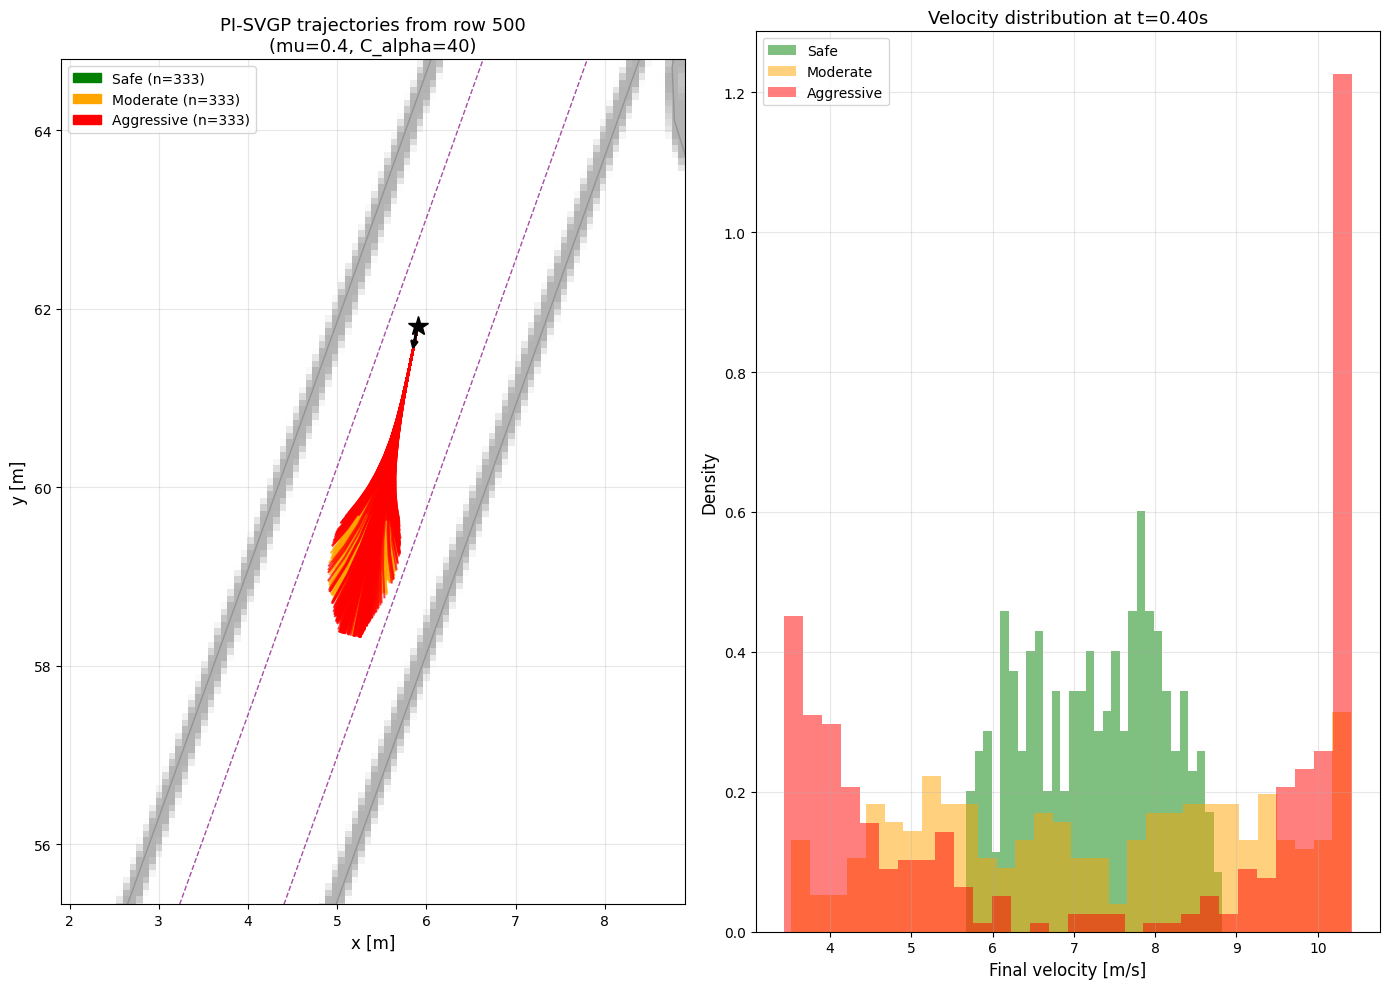


Category         Count  Off-corridor      %  v_end mean  v_end std
----------------------------------------------------------------------
safe               333             0   0.0%        7.25       0.83
moderate           333             0   0.0%        7.22       2.00
aggressive         333             0   0.0%        7.30       2.89


In [22]:
# ── High friction (mu = 1.0489) ──────────────────────────────────────────
ROW_IDX = 500
MU = 0.4

trajs_high, off_high = plot_trajectories_svgp(
    ROW_IDX, df, track_obj,
    map_img=map_img, extent=extent,
    mu=MU, horizon=10, lane_width=1.1,
    # n_aggressive=5, n_moderate=5, n_safe=5,
    n_aggressive=333, n_moderate=333, n_safe=333,

)

Starting state (row 750):
  x=-18.5044  y=-8.3016  delta=0.0572
  v=3.99 m/s  psi=4.6761  omega=2.9461  beta=-0.074989
  mu=0.2  C_alpha=20.00  hp_mu=[-1.10959922 -0.13261857]
  horizon=10  dt=0.04
  Sampling: 333 aggressive, 333 moderate, 333 safe
  aggressive: 333 trajectories in 0.03s
  moderate: 333 trajectories in 0.01s
  safe: 333 trajectories in 0.01s


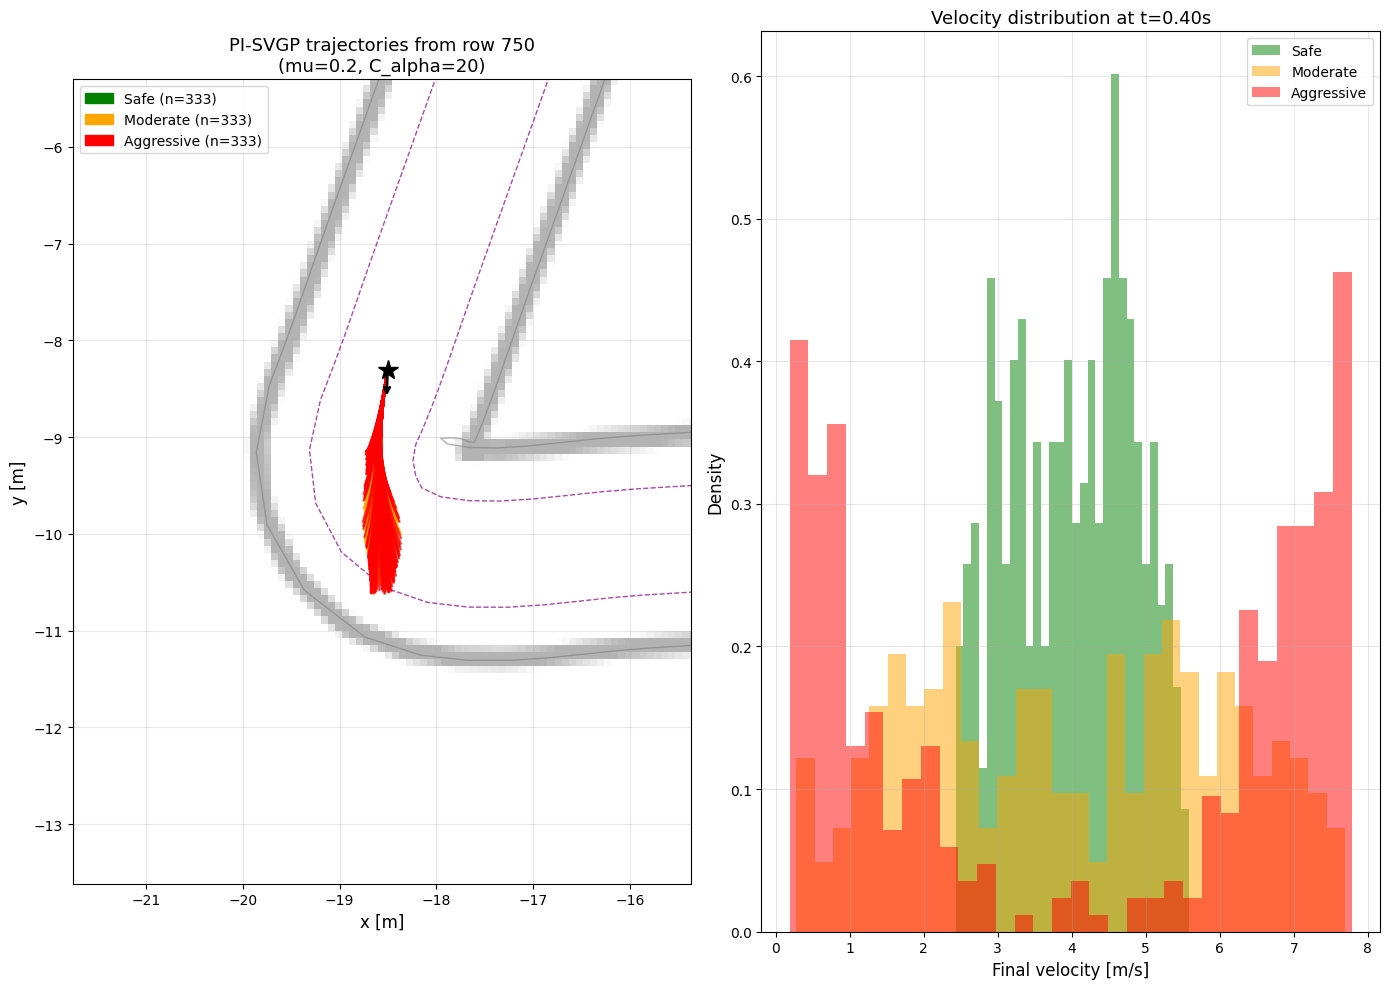


Category         Count  Off-corridor      %  v_end mean  v_end std
----------------------------------------------------------------------
safe               333             0   0.0%        4.01       0.83
moderate           333             0   0.0%        3.99       2.03
aggressive         333             0   0.0%        4.15       2.99


In [21]:
# ── High friction (mu = 1.0489) ──────────────────────────────────────────
ROW_IDX = 750
MU = 0.2

trajs_high, off_high = plot_trajectories_svgp(
    ROW_IDX, df, track_obj,
    map_img=map_img, extent=extent,
    mu=MU, horizon=10, lane_width=1.1,
    n_aggressive=333, n_moderate=333, n_safe=333,
)

Starting state (row 750):
  x=-18.5044  y=-8.3016  delta=0.0572
  v=3.99 m/s  psi=4.6761  omega=2.9461  beta=-0.074989
  mu=0.3  C_alpha=30.00  hp_mu=[-0.64579139  2.60061859]
  horizon=10  dt=0.04
  Sampling: 200 aggressive, 200 moderate, 200 safe
  aggressive: 200 trajectories in 0.04s
  moderate: 200 trajectories in 0.01s
  safe: 200 trajectories in 0.02s


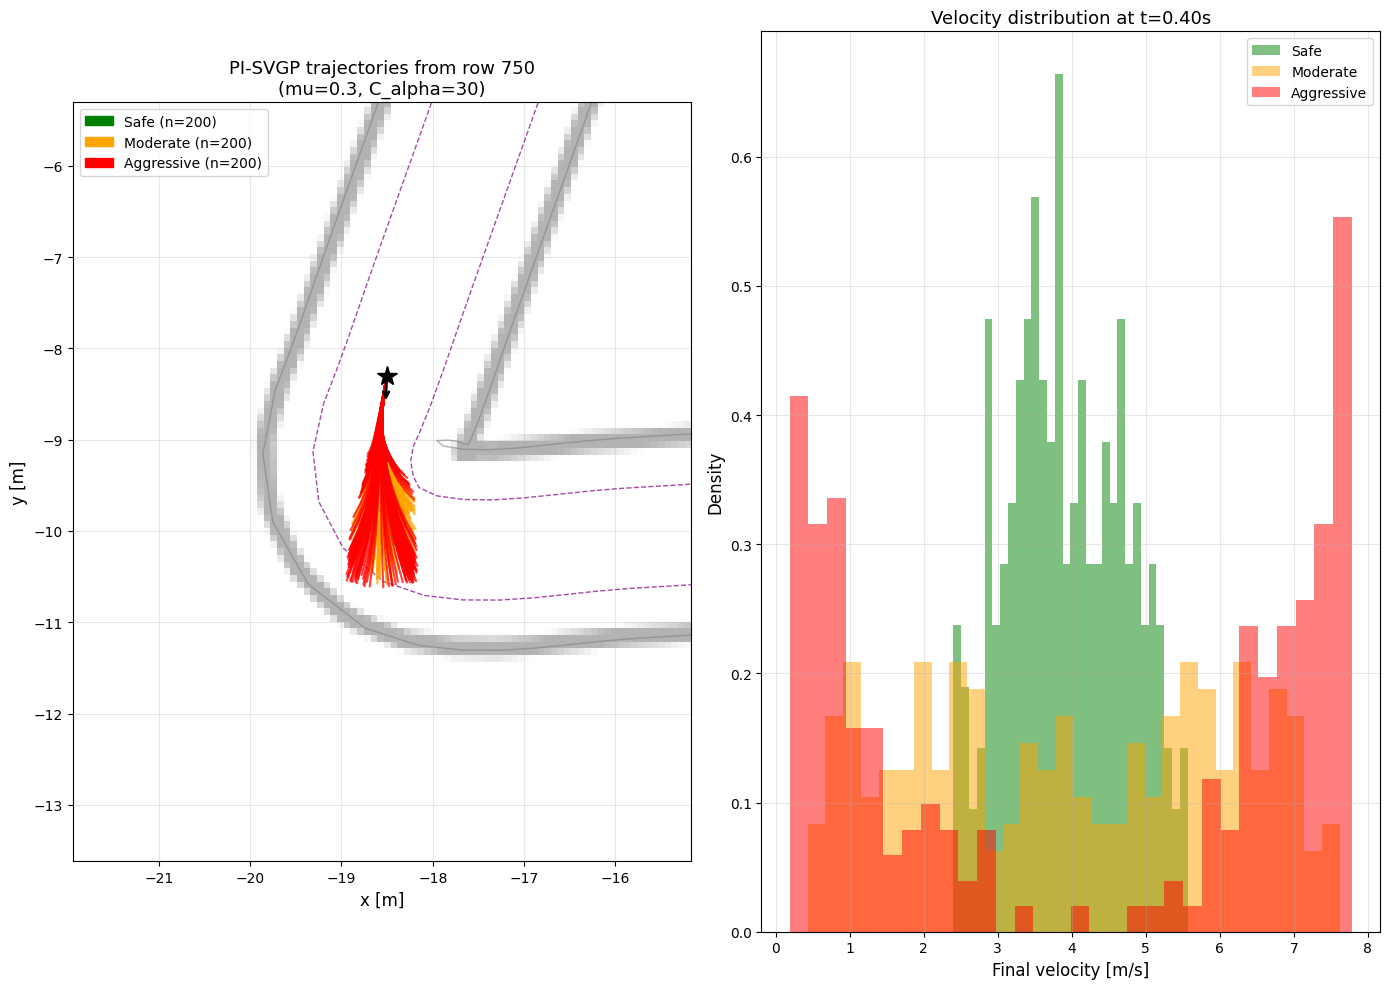


Category         Count  Off-corridor      %  v_end mean  v_end std
----------------------------------------------------------------------
safe               200             0   0.0%        3.92       0.78
moderate           200             0   0.0%        4.00       2.08
aggressive         200             0   0.0%        4.22       3.01


In [10]:
# ── Low friction (mu = 0.3) ──────────────────────────────────────────────
trajs_low, off_low = plot_trajectories_svgp(
    ROW_IDX, df, track_obj,
    map_img=map_img, extent=extent,
    mu=0.3, horizon=10, lane_width=1.1,
    n_aggressive=200, n_moderate=200, n_safe=200,
)

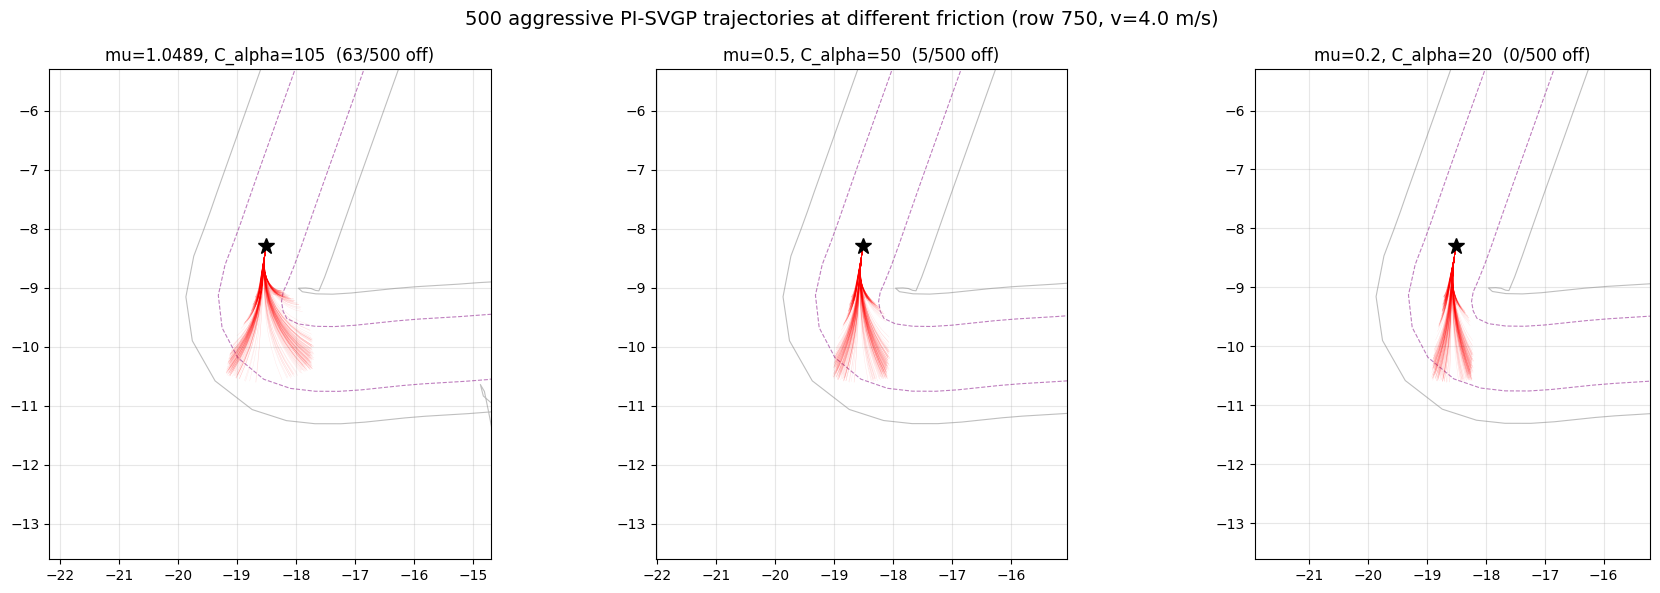

In [11]:
# ── Aggressive-only at different friction levels ─────────────────────────
# Shows how the PI-SVGP model predicts different trajectory spreads
# depending on the inferred friction (C_alpha = mu * 100).

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, mu_val in zip(axes, [1.0489, 0.5, 0.2]):
    row = df.iloc[ROW_IDX]
    state0 = np.array([
        row.S_x, row.S_y, row.S_delta, row.S_vel,
        row.S_psi, row.S_omega, row.S_beta,
    ])

    c_alpha = mu_val * 100.0
    hp_mu = interpolate_hp_mu(c_alpha)

    rng = np.random.default_rng(42)
    actions = sample_actions(500, 'aggressive', rng)

    trajs_np = rollout_svgp_batch(state0, actions, hp_mu, 10)

    # Track boundaries
    ax.plot(track_obj.left_boundary[:, 0], track_obj.left_boundary[:, 1],
            '-', color='gray', linewidth=0.8, alpha=0.5)
    ax.plot(track_obj.right_boundary[:, 0], track_obj.right_boundary[:, 1],
            '-', color='gray', linewidth=0.8, alpha=0.5)
    half_lw = 1.1 / 2.0
    ctrl_left  = track_obj.centerline + track_obj.normal * half_lw
    ctrl_right = track_obj.centerline - track_obj.normal * half_lw
    ax.plot(ctrl_left[:, 0], ctrl_left[:, 1],
            '--', color='purple', linewidth=0.8, alpha=0.5)
    ax.plot(ctrl_right[:, 0], ctrl_right[:, 1],
            '--', color='purple', linewidth=0.8, alpha=0.5)

    n_off = 0
    for i in range(trajs_np.shape[0]):
        ax.plot(trajs_np[i, :, 0], trajs_np[i, :, 1],
                '-', color='red', linewidth=0.3, alpha=0.1)
        for j in range(trajs_np.shape[1]):
            _, dist, _ = track_obj.get_nearest_point(trajs_np[i, j, :2])
            if dist > 1.1 / 2:
                n_off += 1
                break

    ax.plot(state0[0], state0[1], '*', color='black', markersize=12, zorder=10)
    all_x = trajs_np[:, :, 0].flatten()
    all_y = trajs_np[:, :, 1].flatten()
    pad = 3.0
    ax.set_xlim(all_x.min() - pad, all_x.max() + pad)
    ax.set_ylim(all_y.min() - pad, all_y.max() + pad)
    ax.set_aspect('equal')
    ax.set_title(f'mu={mu_val}, C_alpha={c_alpha:.0f}  ({n_off}/500 off)', fontsize=12)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    f'500 aggressive PI-SVGP trajectories at different friction '
    f'(row {ROW_IDX}, v={state0[3]:.1f} m/s)',
    fontsize=14,
)
plt.tight_layout()
plt.show()